## Libraries

In [2]:
from sklearn.datasets import make_blobs
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Import Dataset

In [3]:
X, _ = make_blobs(
    n_samples=5000,
    n_features=2,
    centers=4,
    random_state=42
)

## Finding the EPS


[0.00573726 0.00585396 0.00598191 ... 0.23400699 0.24537264 0.25475201]


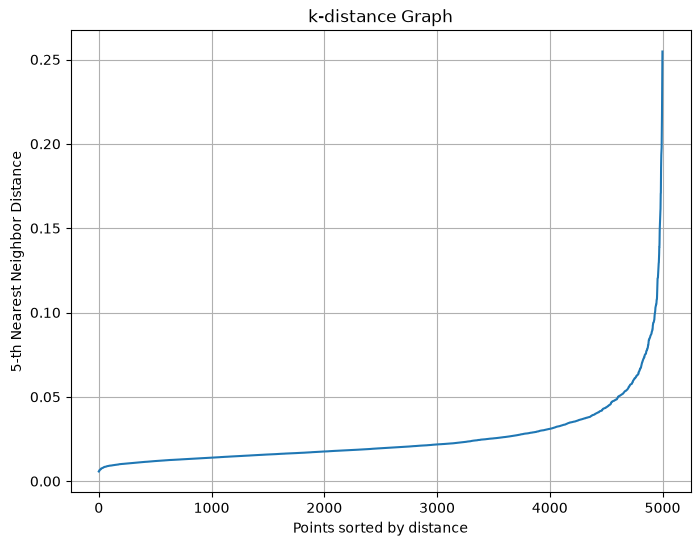

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])
print(k_distances)

plt.figure(figsize=(8, 6))
plt.plot(k_distances)
plt.title('k-distance Graph')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{min_samples}-th Nearest Neighbor Distance')
plt.grid()
plt.show()

## Choose EPS from the Grap

In [8]:
eps_values = [0.05, 0.055, 0.06]

for eps in eps_values:
    model = DBSCAN(
        eps = eps,
        min_samples = 5
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)


    print(f"eps: {eps}, Number of clusters: {n_clusters}, Number of noise points: {n_noise}")

    sizes = pd.Series(labels).value_counts()
    noise_size = sizes.get(-1, 0)
    cluster_sizes = sizes.drop(-1, errors='ignore')

    print(f"\nEPS = {eps}")
    print("Cluster sizes:")
    print(cluster_sizes.sort_values(ascending=False))
    print("Noise points:", noise_size)

eps: 0.05, Number of clusters: 11, Number of noise points: 243

EPS = 0.05
Cluster sizes:
3     1191
0     1182
2     1180
1     1167
9        7
7        6
8        6
6        5
10       5
4        4
5        4
Name: count, dtype: int64
Noise points: 243
eps: 0.055, Number of clusters: 9, Number of noise points: 179

EPS = 0.055
Cluster sizes:
3    1202
0    1199
1    1198
2    1198
7       7
4       5
8       4
5       4
6       4
Name: count, dtype: int64
Noise points: 179
eps: 0.06, Number of clusters: 7, Number of noise points: 129

EPS = 0.06
Cluster sizes:
0    1219
2    1214
3    1214
1    1210
4       5
6       5
5       4
Name: count, dtype: int64
Noise points: 129


In [9]:
for eps in [0.05, 0.055, 0.06]:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    counts = pd.Series(labels).value_counts()

    print(f"\nEPS: {eps}")
    print("min_samples:", model.min_samples)
    print("Cluster sizes:")
    print(counts.drop(index=-1, errors="ignore").sort_values())


EPS: 0.05
min_samples: 5
Cluster sizes:
5        4
4        4
6        5
10       5
8        6
7        6
9        7
1     1167
2     1180
0     1182
3     1191
Name: count, dtype: int64

EPS: 0.055
min_samples: 5
Cluster sizes:
8       4
5       4
6       4
4       5
7       7
1    1198
2    1198
0    1199
3    1202
Name: count, dtype: int64

EPS: 0.06
min_samples: 5
Cluster sizes:
5       4
4       5
6       5
1    1210
2    1214
3    1214
0    1219
Name: count, dtype: int64


In [10]:


for eps in [0.05, 0.055, 0.06]:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    # Identify core points
    core_indices = model.core_sample_indices_

    # Identify clusters with fewer than 5 assigned points
    sizes = pd.Series(labels).value_counts()

    small_clusters = sizes[
        (sizes.index != -1) & (sizes < 5)
    ]

    # Build neighbourhood search
    nn = NearestNeighbors(
        radius=eps,
        metric="euclidean"
    ).fit(X_scaled)

    print(f"\nEPS = {eps}")

    for cluster_id, size in small_clusters.items():

        member_core = core_indices[
            labels[core_indices] == cluster_id
        ]

        print(
            f"\nCluster {cluster_id}: "
            f"size={size}, "
            f"core points={len(member_core)}"
        )

        for point_idx in member_core[:2]:

            neighbors = nn.radius_neighbors(
                X_scaled[point_idx].reshape(1, -1),
                return_distance=False
            )[0]

            print("Core point:", point_idx)
            print("Total neighbours:", len(neighbors))

            print(
                "Neighbour labels:",
                pd.Series(labels[neighbors])
                .value_counts().to_dict()
            )


EPS = 0.05

Cluster 4: size=4, core points=2
Core point: 801
Total neighbours: 5
Neighbour labels: {4: 4, 3: 1}
Core point: 3084
Total neighbours: 5
Neighbour labels: {4: 4, 3: 1}

Cluster 5: size=4, core points=1
Core point: 1404
Total neighbours: 5
Neighbour labels: {5: 4, 1: 1}

EPS = 0.055

Cluster 8: size=4, core points=1
Core point: 4610
Total neighbours: 5
Neighbour labels: {8: 4, 1: 1}

Cluster 5: size=4, core points=1
Core point: 1404
Total neighbours: 5
Neighbour labels: {5: 4, 1: 1}

Cluster 6: size=4, core points=1
Core point: 1895
Total neighbours: 5
Neighbour labels: {6: 4, 3: 1}

EPS = 0.06

Cluster 5: size=4, core points=1
Core point: 1404
Total neighbours: 5
Neighbour labels: {5: 4, 1: 1}


## Use the Silhouette Score

In [11]:
from sklearn.metrics import silhouette_score

eps_values = [0.05, 0.055, 0.06]

for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)

    mask = labels != -1

    X_clustered = X_scaled[mask]
    cluster_labels = labels[mask]

    n_clusters = len(set(cluster_labels))
    n_noise = np.sum(labels == -1)

    noise_percentage = (n_noise / len(labels)) * 100

    print(f"\nEPS = {eps}")
    print("Clusters:", n_clusters)
    print("Noise percentage:", round(noise_percentage, 2))

    if 2 <= n_clusters < len(cluster_labels):
        score = silhouette_score(
            X_clustered,
            cluster_labels
        )
        print("Silhouette Score:", round(score, 4))
    else:
        print("Silhouette Score: Not valid")



EPS = 0.05
Clusters: 11
Noise percentage: 4.86
Silhouette Score: 0.2729

EPS = 0.055
Clusters: 9
Noise percentage: 3.58
Silhouette Score: 0.3528

EPS = 0.06
Clusters: 7
Noise percentage: 2.58
Silhouette Score: 0.5348


## Interpreting cluster profiles

In [17]:
model = DBSCAN(
    eps=0.06,
    min_samples=5
)

labels = model.fit_predict(X_scaled)

X_original = pd.DataFrame(X)

clustered_data = X_original.copy()
clustered_data["Cluster"] = labels


valid_data = clustered_data[
    clustered_data["Cluster"] != -1
]

# Generate cluster profile
profile = valid_data.groupby("Cluster").agg(
    Count=("Cluster", "size"),
    Mean_Values=(X_original.columns[0], "mean")
)

print(profile)

         Count  Mean_Values
Cluster                    
0         1219     4.625030
1         1210    -6.904460
2         1214    -8.839378
3         1214    -2.481291
4            5    -5.075705
5            4    -3.985053
6            5    -4.816302
